# 09 — PCA, Horn's parallel analysis, and a K-unit autoencoder map

**What this notebook does.** Same 391 speakers and 25 features as NB08 — read from NB08's exports,
because NB08 is where the features are built, validated and gated. (1) Runs PCA on the standardized
features and uses Horn's parallel analysis to decide how many components carry more than noise (K).
(2) Rebuilds the autoencoder with a K-unit bottleneck instead of NB08's 3. (3) Finishes the same way as
NB08: stability, cluster tests with a null and a power calibration, what the units mean, demographics,
forced clusters scored by V-measure, graphs, sensitivity variants, and a verdict table. PCA at the same K
(the linear version of the same compression) and NB08's 3-unit autoencoder ride along as comparisons.

**Decisions ledger** (2026-09-29, Dain: "on a new notebook, do pca, check how many horns retains, do the
encoder with horns components retained # as the bottle neck, then finish off the same way"):
- **Inputs:** `utterances_v2/derived/nb08_speaker_map.csv` (Kelley estimates of the 25 gated features,
  demographics, the book-signed composite) and `nb08_side_values.csv` (per-side values for the
  sensitivity variants); the standardized matrix is rebuilt with NB08's transform (Yeo–Johnson + z).
- **Horn's parallel analysis:** primary = NB07's convention — independent normal data of the same shape,
  the 95th percentile of each rank's eigenvalue over 1,000 draws, K = the leading eigenvalues above it.
  Beside it: the column-shuffle null (Buja & Eyuboglu 1992), Horn's original mean rule, and K's
  stability over 200 subsamples of 80% of the speakers (drawn without replacement; the notebook shows on
  pure noise why resampling *with* replacement cannot be used for this).
- **Autoencoder:** bottleneck = K; width and weight penalty re-chosen by the same 5-fold held-out
  reconstruction; 20 restarts; the medoid restart is the map.
- **Everything after that exactly as NB08**, applied to the K-unit code. The 3-D graphs show the code's
  three largest-variance directions — a rotation for display only, with the share of the code shown.

**Honesty framing.** Horn's K was previewed once on this data before this notebook was written (K = 5; the
6th eigenvalue 1.250 missed its threshold 1.256). The rule is NB07's and was chosen before the preview;
every other rule is NB08's, unchanged.

In [1]:
# Provenance, imports, constants.
import subprocess, sys, datetime, time
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn
from scipy.stats import spearmanr, norm
from scipy.spatial.distance import pdist
from diptest import diptest
from sklearn.decomposition import PCA
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import (roc_auc_score, homogeneity_completeness_v_measure, adjusted_mutual_info_score,
                             v_measure_score, mutual_info_score)
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from swb_extract.speaker_map import (bh_fdr, encode, fit_ae, gmm_best_k, copula_sampler, horn, icc1,
                                     kelley_table, write_map_html)

REPO = Path("..").resolve()
DERIVED = REPO / "utterances_v2" / "derived"
T_START = time.time()
_git = lambda *a: subprocess.run(["git", "-C", str(REPO), *a], capture_output=True, text=True).stdout.strip()
print(f"NB09 · {datetime.date.today()} · HEAD {_git('rev-parse', '--short', 'HEAD')}"
      f"{' + uncommitted changes' if _git('status', '--porcelain') else ''} · python {sys.version.split()[0]}"
      f" · numpy {np.__version__} · pandas {pd.__version__} · scikit-learn {sklearn.__version__} · scipy {scipy.__version__}")

AE_SEEDS, N_NULL, POWER_REPS, N_PERM, CV_SEEDS, HORN_B, HORN_BOOT = 20, 30, 20, 1000, 5, 1000, 200

def elapsed():
    return f"[{time.time() - T_START:,.0f} s]"

NB09 · 2026-09-29 · HEAD 0efd102 + uncommitted changes · python 3.14.0 · numpy 2.4.4 · pandas 3.0.5 · scikit-learn 1.8.0 · scipy 1.17.1


## S0 — Inputs from NB08

**Check:** the export has exactly NB08's 25 gated features for 391 speakers, the side table covers the
same callers, and — a cross-notebook check made in S2 — re-fitting NB08's 3-unit autoencoder here on the
rebuilt matrix must reproduce NB08's exported map coordinates.

In [2]:
SPK = pd.read_csv(DERIVED / "nb08_speaker_map.csv", index_col="caller")
SIDE = pd.read_csv(DERIVED / "nb08_side_values.csv")
ICC08 = pd.read_csv(DERIVED / "nb08_feature_icc.csv", index_col="feature")
FEATS = list(SPK.columns[: SPK.columns.get_loc("ae1")])
assert len(FEATS) == 25 and ICC08.loc[FEATS, "speaker component"].astype(bool).all()
assert len(SPK) == 391 and len(SIDE) == 1972 and set(SIDE["caller"]) == set(SPK.index) and set(FEATS) <= set(SIDE.columns)
assert SPK[FEATS].notna().all().all()
for f_ in ("nb08_speaker_map.csv", "nb08_side_values.csv"):
    print(f"{f_}: written {datetime.datetime.fromtimestamp((DERIVED / f_).stat().st_mtime):%Y-%m-%d %H:%M}")
X = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(SPK[FEATS])
DEMO = SPK[["sex", "birth_year", "dialect", "education", "female"]].copy()
composite, n_sides = SPK["tannen_composite"], SPK["n_sides"]
yF = DEMO["female"].to_numpy(); fem = yF == 1
edu_m = DEMO["education"].isin([0, 1, 2, 3]).to_numpy()
print(f"{len(SPK)} speakers × {len(FEATS)} features · {len(SIDE):,} conversation sides · {DEMO['sex'].value_counts().to_dict()}")

nb08_speaker_map.csv: written 2026-09-29 15:06
nb08_side_values.csv: written 2026-09-29 15:06
391 speakers × 25 features · 1,972 conversation sides · {'MALE': 199, 'FEMALE': 192}


## S1 — PCA and Horn's parallel analysis

**What PCA does:** it finds the directions along which the 25 standardized features vary together, ranked
by how much variance each carries. A direction's **eigenvalue** is how many features' worth of variance it
holds (25 in total, so 1.0 = one feature's worth).

**Horn's question:** how many of those directions carry more than chance? Random data of the same size
also produces eigenvalues above 1 — sampling noise alone makes some directions look big, the way 391 coin
flips per column still line up a little by accident. So each observed eigenvalue is compared with the 95th
percentile of the same-rank eigenvalue across 1,000 random datasets, and components are kept while they
beat that line. K is the answer; the autoencoder in S2 gets K bottleneck units.

           eigenvalue  % variance  cumulative %  normal 95th  shuffle 95th  normal mean
component                                                                              
1               3.348      13.391        13.391        1.563         1.567        1.491
2               3.080      12.320        25.711        1.471         1.469        1.413
3               1.936       7.746        33.457        1.402         1.402        1.356
4               1.721       6.885        40.342        1.347         1.347        1.306
5               1.550       6.199        46.541        1.297         1.300        1.261
6               1.250       5.001        51.543        1.256         1.253        1.221
7               1.180       4.721        56.264        1.216         1.212        1.182
8               1.032       4.129        60.393        1.177         1.176        1.146
9               0.994       3.974        64.367        1.140         1.140        1.111
10              0.911       3.64

pure noise of the same shape: full sample K = 0; resampled WITH replacement → K = 3: 1, K = 4: 1, K = 5: 10, K = 6: 11, K = 7: 16, K = 8: 18, K = 9: 28, K = 10: 8, K = 11: 6, K = 12: 1; 80% subsamples without → K = 0: 100


speakers, 200 subsamples of 80% without replacement: K = 5: 117, K = 6: 75, K = 7: 8  [6 s]

PCA loadings (feature–component correlations) of the retained components:
  PC1 (13.4%)  low: fto_mean -0.64, words_per_unit -0.59, obstr_share -0.42, opinion_share -0.24 | high: coop_overlap_rate +0.70, appreciation_rate +0.64, bc_rate +0.49, gold_laughter_rate +0.44
  PC2 (12.3%)  low: gold_laughter_rate -0.43, q_rate -0.41, fto_mean -0.39, filled_pause_rate -0.32 | high: word_share +0.73, syllable_rate +0.71, repu +0.70, words_per_unit +0.55
  PC3 (7.7%)  low: quote_rate -0.27, obstr_share -0.16, ppron_per_word -0.13, syllable_rate -0.11 | high: restart_rate +0.75, filled_pause_rate +0.70, within_pause_rate +0.61, bc_rate +0.29
  PC4 (6.9%)  low: coop_overlap_rate -0.38, opinion_share -0.15, latch_share -0.08, bc_rate -0.06 | high: hedge_rate +0.51, obstr_share +0.50, ppron_per_word +0.47, q_rate +0.45
  PC5 (6.2%)  low: latch_share -0.49, obstr_share -0.29, elaboration_share -0.24, filled_p

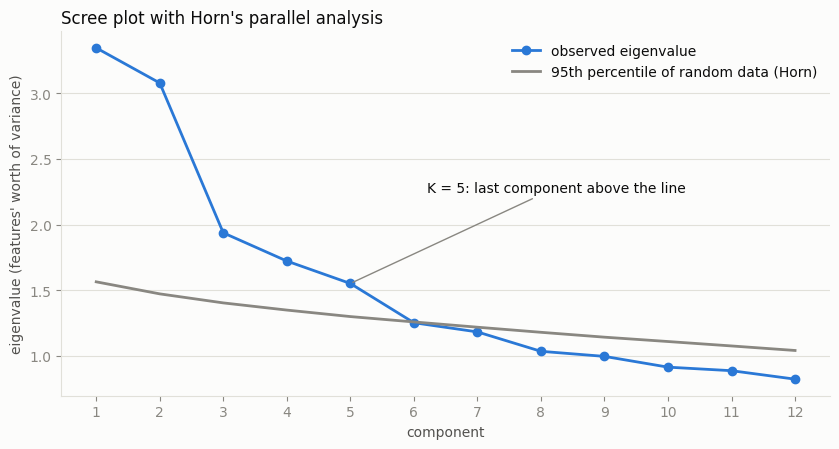

In [3]:
HN = horn(X, B=HORN_B, seed=0, null="normal")
HP = horn(X, B=HORN_B, seed=0, null="permute")
K = HN["K"]
P_ = X.shape[1]
TAB = pd.DataFrame({"eigenvalue": HN["eig"], "% variance": 100 * HN["eig"] / P_, "cumulative %": 100 * np.cumsum(HN["eig"]) / P_,
                    "normal 95th": HN["thr"], "shuffle 95th": HP["thr"], "normal mean": HN["mean"]}, index=np.arange(1, P_ + 1))
TAB.index.name = "component"
print(TAB.head(10).round(3).to_string())
print(f"\nHorn K — normal null, 95th percentile (primary): {K}; column-shuffle null: {HP['K']}; Horn's mean rule: "
      f"{HN['K_mean']} (normal) / {HP['K_mean']} (shuffle)")
print(f"the first {K} components carry {TAB['cumulative %'].iloc[K - 1]:.1f}% of the variance; component {K + 1}: eigenvalue "
      f"{HN['eig'][K]:.3f} vs threshold {HN['thr'][K]:.3f}")
# How stable is K? Re-run Horn on 80% subsamples of speakers drawn WITHOUT replacement. (Resampling with
# replacement is not usable here: duplicated speakers manufacture shared variance. Shown on pure noise,
# where the right answer is K = 0.)
_rng = np.random.default_rng(1)
_noise = _rng.standard_normal(X.shape)
_kc = lambda a: ", ".join(f"K = {k}: {c}" for k, c in zip(*np.unique(a, return_counts=True)))
_nb = np.array([horn(_noise[_rng.integers(0, len(X), len(X))], B=200, seed=b)["K"] for b in range(100)])
_ns = np.array([horn(_noise[_rng.choice(len(X), int(0.8 * len(X)), replace=False)], B=200, seed=b)["K"] for b in range(100)])
print(f"pure noise of the same shape: full sample K = {horn(_noise, B=200, seed=0)['K']}; resampled WITH replacement → {_kc(_nb)}; "
      f"80% subsamples without → {_kc(_ns)}")
KSUB = np.array([horn(X[_rng.choice(len(X), int(0.8 * len(X)), replace=False)], B=200, seed=b)["K"] for b in range(HORN_BOOT)])
print(f"speakers, {HORN_BOOT} subsamples of 80% without replacement: {_kc(KSUB)}  {elapsed()}")

pca = PCA(n_components=K).fit(X)
PC = pca.transform(X)
LOAD = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index=FEATS, columns=[f"PC{j + 1}" for j in range(K)])
print("\nPCA loadings (feature–component correlations) of the retained components:")
for j in range(K):
    col = LOAD[f"PC{j + 1}"].sort_values()
    print(f"  PC{j + 1} ({100 * pca.explained_variance_ratio_[j]:.1f}%)  low: " + ", ".join(f"{f} {v:+.2f}" for f, v in col.head(4).items())
          + " | high: " + ", ".join(f"{f} {v:+.2f}" for f, v in col.tail(4)[::-1].items()))

INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"font.family": "sans-serif", "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED,
                     "ytick.color": MUTED, "figure.facecolor": SURF, "axes.facecolor": SURF, "grid.color": GRID})
fig, ax = plt.subplots(figsize=(8.5, 4.6))
r_ = np.arange(1, 13)
ax.plot(r_, HN["eig"][:12], color=BLUE, lw=2, marker="o", ms=6, label="observed eigenvalue")
ax.plot(r_, HN["thr"][:12], color=MUTED, lw=2, label="95th percentile of random data (Horn)")
ax.annotate(f"K = {K}: last component above the line", xy=(K, HN["eig"][K - 1]), xytext=(K + 1.2, HN["eig"][K - 1] + 0.7),
            color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.set_xticks(r_); ax.set_xlabel("component"); ax.set_ylabel("eigenvalue (features' worth of variance)")
ax.grid(axis="y", lw=0.8); ax.set_axisbelow(True)
for side_ in ("top", "right"):
    ax.spines[side_].set_visible(False)
for side_ in ("left", "bottom"):
    ax.spines[side_].set_color(GRID)
ax.legend(frameon=False)
ax.set_title("Scree plot with Horn's parallel analysis", loc="left", color=INK)
plt.tight_layout(); plt.show()

## S2 — The K-unit autoencoder

Same network family as NB08 (25 → h → K → h → 25, tanh), now with **K** bottleneck units. Width h and
weight penalty α are re-chosen by 5-fold held-out reconstruction; then 20 restarts and the medoid restart,
as in NB08. **Comparisons, all on held-out callers:** PCA with K components (the best *linear* K-number
summary — if the autoencoder cannot beat it, its bends buy nothing), NB08's 3-unit autoencoder and PCA
with 3 components (what the extra units add), and the K-unit autoencoder on column-shuffled data (what K
units hold when the features share nothing). **Cross-notebook check:** the 3-unit autoencoder re-fitted
here with NB08's settings must reproduce NB08's exported coordinates.

In [4]:
def cv_recon(fit_predict, X=X):
    num = den = 0.0
    for tr, te in KFold(5, shuffle=True, random_state=0).split(X):
        P = fit_predict(X[tr], X[te])
        num += ((X[te] - P) ** 2).sum(); den += ((X[te] - X[tr].mean(0)) ** 2).sum()
    return 1 - num / den
ae_fp = lambda h, a, k: (lambda tr, te: fit_ae(tr, 0, h, a, k=k).predict(te))
pca_fp = lambda k: (lambda tr, te: (lambda m: m.inverse_transform(m.transform(te)))(PCA(n_components=k).fit(tr)))
grid = pd.DataFrame([(h, a, cv_recon(ae_fp(h, a, K))) for h in (8, 16, 32) for a in (1e-4, 1e-3, 1e-2, 1e-1)],
                    columns=["h", "alpha", "held-out R²"])
best = grid.loc[grid["held-out R²"].idxmax()]
H, ALPHA = int(best["h"]), float(best["alpha"])
print(grid.pivot(index="h", columns="alpha", values="held-out R²").round(4).to_string())
_rng = np.random.default_rng(5)
X_indep = np.column_stack([_rng.permutation(X[:, j]) for j in range(X.shape[1])])
RECON = {f"autoencoder, {K} units": best["held-out R²"], f"PCA, {K} components": cv_recon(pca_fp(K)),
         "autoencoder, 3 units (NB08)": cv_recon(ae_fp(8, 0.1, 3)), "PCA, 3 components": cv_recon(pca_fp(3)),
         f"autoencoder, {K} units, column-shuffled data": cv_recon(ae_fp(H, ALPHA, K), X=X_indep)}
print(f"chosen: h = {H}, α = {ALPHA:g}. Held-out reconstruction R²:")
for k_, v_ in RECON.items():
    print(f"  {k_:44s} {v_:.3f}")

def restarts(k, h, alpha):
    ms = [fit_ae(X, s, h, alpha, k=k) for s in range(AE_SEEDS)]
    cs = [encode(m, X) for m in ms]
    ds = [pdist(z) for z in cs]
    Mv = np.array([[spearmanr(ds[i], ds[j])[0] if i != j else np.nan for j in range(AE_SEEDS)] for i in range(AE_SEEDS)])
    return ms, cs, Mv, int(np.nanargmax(np.nanmean(Mv, 1)))
models, codes, M, MED = restarts(K, H, ALPHA)
Z, ae = codes[MED], models[MED]
models3, codes3, M3, MED3 = restarts(3, 8, 0.1)
Z3u = codes3[MED3]
print(f"cross-notebook check — NB08's 3-unit map re-fitted here: medoid seed {MED3}, max |difference| from NB08's "
      f"exported coordinates {np.abs(Z3u - SPK[['ae1', 'ae2', 'ae3']].to_numpy()).max():.2e}")
if AE_SEEDS == 20:     # NB08's medoid is defined over 20 restarts; a smoke run with fewer cannot reproduce it
    assert np.allclose(Z3u, SPK[["ae1", "ae2", "ae3"]].to_numpy(), atol=1e-6)
PC3 = PCA(n_components=3).fit_transform(X)
knn_sets = lambda z: NearestNeighbors(n_neighbors=11).fit(z).kneighbors(z, return_distance=False)[:, 1:]
k_med = knn_sets(Z)
overlap = [np.mean([len(set(a) & set(b)) / 10 for a, b in zip(k_med, knn_sets(z))]) for i, z in enumerate(codes) if i != MED]
fit_r2 = [1 - ((X - m.predict(X)) ** 2).sum() / ((X - X.mean(0)) ** 2).sum() for m in models]
STAB = dict(fit_r2_min=min(fit_r2), fit_r2_max=max(fit_r2), dist_rho_median=np.nanmedian(M), dist_rho_min=np.nanmin(M),
            med_seed=MED, knn_overlap_median=np.median(overlap), knn_chance=10 / (len(X) - 1),
            trust=trustworthiness(X, Z, n_neighbors=10), iters_max=max(m.n_iter_ for m in models))
print(f"{AE_SEEDS} restarts of the {K}-unit autoencoder: in-sample R² {STAB['fit_r2_min']:.3f}–{STAB['fit_r2_max']:.3f}; distance "
      f"agreement median ρ {STAB['dist_rho_median']:.3f} (min {STAB['dist_rho_min']:.3f}); medoid seed {MED}; 10-NN overlap "
      f"{STAB['knn_overlap_median']:.2f} (chance {STAB['knn_chance']:.3f}); trustworthiness {STAB['trust']:.3f}; iterations ≤ {STAB['iters_max']}")
PER_FEAT = pd.DataFrame({f"autoencoder {K}": 1 - ((X - ae.predict(X)) ** 2).sum(0) / ((X - X.mean(0)) ** 2).sum(0),
                         f"PCA {K}": 1 - ((X - pca.inverse_transform(PC)) ** 2).sum(0) / ((X - X.mean(0)) ** 2).sum(0)}, index=FEATS)
print("how much of each feature the code carries (in-sample R²), autoencoder vs PCA:")
print("  " + " · ".join(f"{f} {a:.2f}/{b:.2f}" for f, (a, b) in PER_FEAT.sort_values(f"autoencoder {K}", ascending=False).iterrows()))
print(f"  code saturation (|z| > .95): {(np.abs(Z) > 0.95).mean():.3f}  {elapsed()}")

alpha  0.0001  0.0010  0.0100  0.1000
h                                    
8      0.4150  0.4150  0.4150  0.4144
16     0.4142  0.4142  0.4143  0.4114
32     0.4009  0.4009  0.4010  0.4034


chosen: h = 8, α = 0.0001. Held-out reconstruction R²:
  autoencoder, 5 units                         0.415
  PCA, 5 components                            0.429
  autoencoder, 3 units (NB08)                  0.298
  PCA, 3 components                            0.310
  autoencoder, 5 units, column-shuffled data   0.183


cross-notebook check — NB08's 3-unit map re-fitted here: medoid seed 7, max |difference| from NB08's exported coordinates 1.40e-08
20 restarts of the 5-unit autoencoder: in-sample R² 0.450–0.460; distance agreement median ρ 0.951 (min 0.900); medoid seed 19; 10-NN overlap 0.73 (chance 0.026); trustworthiness 0.879; iterations ≤ 1507
how much of each feature the code carries (in-sample R²), autoencoder vs PCA:
  coop_overlap_rate 0.77/0.77 · filled_pause_rate 0.69/0.67 · words_per_unit 0.68/0.69 · restart_rate 0.65/0.65 · word_share 0.65/0.65 · syllable_rate 0.64/0.65 · repu 0.61/0.61 · fto_mean 0.60/0.60 · opinion_share 0.57/0.58 · hedge_rate 0.54/0.47 · obstr_share 0.51/0.55 · ppron_per_word 0.47/0.44 · gold_laughter_rate 0.45/0.43 · completion_rate 0.45/0.48 · latch_share 0.41/0.42 · appreciation_rate 0.40/0.42 · quote_rate 0.39/0.40 · q_rate 0.37/0.41 · echo_q_rate 0.37/0.41 · within_pause_rate 0.34/0.42 · bc_rate 0.34/0.34 · mirror_rate 0.22/0.22 · elaboration_share 0.16/0.16 · lou

## S3 — Do speakers form clusters?

The same battery as NB08 S7, now in the K-unit code (and in the K PCA scores): Gaussian-mixture BIC for
k = 1…8, Hartigan's dip on pairwise distances, 30 structureless twins (same marginals and correlations,
one blob) through the identical K-unit pipeline, planted two-group power at Mahalanobis Δ = 0…6, and a
t-SNE view of the K-unit code with its own twin null — t-SNE is the method most prone to drawing groups
that are not there, so its twins matter more than its own result. Clusters are claimed only if BIC
prefers k ≥ 2 in the code and in the full space beyond the null — NB08's rule.

In [5]:
def dip_dist(F):
    return diptest(np.random.default_rng(0).choice(pdist(F), 50_000, replace=False))
SPACES = {f"autoencoder {K}-D": (Z, "full"), f"PCA {K}-D": (PC, "full"), "full 25-D": (X, "tied")}
CL = {name: (*gmm_best_k(F, cov), *dip_dist(F)) for name, (F, cov) in SPACES.items()}
for name, (k_, gain_, d_, p_) in CL.items():
    print(f"  {name:16s} best k = {k_} (BIC gain {gain_:.1f}); distance dip {d_:.4f}, p {p_:.3f}")
draw, R_ns = copula_sampler(X)
_rng, null_rows = np.random.default_rng(1), []
for rep in range(N_NULL):
    Xn = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(draw(_rng))
    null_rows.append((gmm_best_k(encode(fit_ae(Xn, MED, H, ALPHA, k=K), Xn), "full")[0],
                      gmm_best_k(PCA(n_components=K).fit_transform(Xn), "full")[0]))
NULL = pd.DataFrame(null_rows, columns=["k_code", "k_pca"])
print(f"null ({N_NULL} twins): k = 1 in {(NULL.k_code == 1).mean():.0%} (autoencoder) / {(NULL.k_pca == 1).mean():.0%} (PCA)  {elapsed()}")
Rinv, L = np.linalg.inv(R_ns), np.linalg.cholesky(R_ns)
_rng, power_rows = np.random.default_rng(11), []
for Delta in (0, 2, 3, 4, 5, 6):
    hit_code = hit_pca = 0
    for rep in range(POWER_REPS):
        G = _rng.standard_normal(X.shape) @ L.T
        lab = _rng.random(len(X)) < 0.5
        v = _rng.standard_normal(X.shape[1]); s_ = Delta / np.sqrt(v @ Rinv @ v) if Delta else 0.0
        Xp = StandardScaler().fit_transform(G + np.outer(np.where(lab, 0.5, -0.5), s_ * v))
        hit_code += gmm_best_k(encode(fit_ae(Xp, MED, H, ALPHA, k=K), Xp), "full", kmax=5)[0] >= 2
        hit_pca += gmm_best_k(PCA(n_components=K).fit_transform(Xp), "full", kmax=5)[0] >= 2
    power_rows.append((Delta, hit_code / POWER_REPS, hit_pca / POWER_REPS))
POWER = pd.DataFrame(power_rows, columns=["Mahalanobis Δ", f"detected, autoencoder {K}-D", f"detected, PCA {K}-D"])
print(POWER.to_string(index=False, formatters={c: "{:.0%}".format for c in POWER.columns[1:]}))
tsne = [TSNE(n_components=3, perplexity=30, init="random", random_state=s).fit_transform(Z) for s in range(5)]
_rng = np.random.default_rng(3)
tsne_null_k = []
for s in range(5):
    Xn = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(draw(_rng))
    Zn = encode(fit_ae(Xn, MED, H, ALPHA, k=K), Xn)
    tsne_null_k.append(gmm_best_k(TSNE(n_components=3, perplexity=30, init="random", random_state=s).fit_transform(Zn), "full")[0])
tsne_k = [gmm_best_k(t_, "full")[0] for t_ in tsne]
print(f"t-SNE of the {K}-unit code: best k per seed {tsne_k}; t-SNE of the twins' codes {tsne_null_k}")
k_code, k_full = CL[f"autoencoder {K}-D"][0], CL["full 25-D"][0]
CLUSTERS = (k_code >= 2) and (k_full >= 2)
print(f"\nVERDICT — clusters by NB08's rule: {'YES' if CLUSTERS else 'NO'}. Two equal groups are detected ≥50% of the time from Δ ≈ "
      f"{POWER.loc[POWER.iloc[:, 1] >= 0.5, 'Mahalanobis Δ'].min()} (autoencoder) / {POWER.loc[POWER.iloc[:, 2] >= 0.5, 'Mahalanobis Δ'].min()} "
      f"(PCA); false alarms at Δ = 0: {POWER.iloc[0, 1]:.0%} / {POWER.iloc[0, 2]:.0%}.  {elapsed()}")

  autoencoder 5-D  best k = 1 (BIC gain 0.0); distance dip 0.0009, p 0.995
  PCA 5-D          best k = 1 (BIC gain 0.0); distance dip 0.0010, p 0.992
  full 25-D        best k = 1 (BIC gain 0.0); distance dip 0.0008, p 0.998


null (30 twins): k = 1 in 100% (autoencoder) / 100% (PCA)  [79 s]


 Mahalanobis Δ detected, autoencoder 5-D detected, PCA 5-D
             0                        0%                0%
             2                        0%                0%
             3                        0%                0%
             4                        0%                0%
             5                       75%               60%
             6                      100%               95%


t-SNE of the 5-unit code: best k per seed [3, 3, 3, 3, 2]; t-SNE of the twins' codes [4, 1, 2, 3, 2]

VERDICT — clusters by NB08's rule: NO. Two equal groups are detected ≥50% of the time from Δ ≈ 5 (autoencoder) / 5 (PCA); false alarms at Δ = 0: 0% / 0%.  [156 s]


## S4 — What the K units mean

**Read-out:** the Spearman correlation of each unit with each feature (units are unordered and their signs
arbitrary; their content is what they correlate with), beside PCA's loadings from S1. **How linear is the
code?** Each autoencoder unit is predicted from the K PCA scores by cross-validated linear regression: R²
near 1 means the unit is a rotation of PCA's subspace, lower means it bends. **Theory check** as in NB08:
the book-signed composite (computed in NB08 without any compression) read back from each representation.

In [6]:
AXU = pd.DataFrame({f"unit {j + 1}": [spearmanr(Z[:, j], X[:, i])[0] for i in range(len(FEATS))] for j in range(K)}, index=FEATS)
for j in range(K):
    col = AXU[f"unit {j + 1}"].sort_values()
    print(f"unit {j + 1}  low: " + ", ".join(f"{f} {v:+.2f}" for f, v in col.head(4).items())
          + " | high: " + ", ".join(f"{f} {v:+.2f}" for f, v in col.tail(4)[::-1].items()))
ridge = lambda: RidgeCV(alphas=np.logspace(-3, 3, 13))
LIN = [cross_val_score(ridge(), PC, Z[:, j], cv=KFold(10, shuffle=True, random_state=0), scoring="r2").mean() for j in range(K)]
print(f"\neach autoencoder unit from the {K} PCA scores (CV R²): " + ", ".join(f"{v:.2f}" for v in LIN))
readout = lambda F: cross_val_score(ridge(), F, composite, cv=KFold(10, shuffle=True, random_state=0), scoring="r2").mean()
READ = {f"autoencoder {K}": readout(Z), f"PCA {K}": readout(PC), "autoencoder 3 (NB08)": readout(Z3u), "PCA 3": readout(PC3), "full 25-D": readout(X)}
READ_RESTARTS = np.array([readout(z) for z in codes])
print("book-signed composite read back (CV R²): " + "; ".join(f"{k} {v:.3f}" for k, v in READ.items())
      + f"; {K}-unit restarts {READ_RESTARTS.min():.3f}–{READ_RESTARTS.max():.3f}")

unit 1  low: latch_share -0.44, elaboration_share -0.20, filled_pause_rate -0.17, words_per_unit -0.08 | high: hedge_rate +0.69, completion_rate +0.46, opinion_share +0.43, q_rate +0.30
unit 2  low: obstr_share -0.62, fto_mean -0.41, ppron_per_word -0.28, q_rate -0.25 | high: coop_overlap_rate +0.62, completion_rate +0.35, opinion_share +0.35, bc_rate +0.33
unit 3  low: gold_laughter_rate -0.44, coop_overlap_rate -0.40, appreciation_rate -0.38, ppron_per_word -0.34 | high: words_per_unit +0.69, restart_rate +0.65, filled_pause_rate +0.49, word_share +0.36
unit 4  low: syllable_rate -0.57, quote_rate -0.54, repu -0.49, word_share -0.43 | high: filled_pause_rate +0.69, within_pause_rate +0.44, restart_rate +0.43, q_rate +0.35
unit 5  low: word_share -0.48, repu -0.45, appreciation_rate -0.43, bc_rate -0.40 | high: fto_mean +0.45, opinion_share +0.31, words_per_unit +0.11, obstr_share -0.01

each autoencoder unit from the 5 PCA scores (CV R²): 0.98, 0.99, 0.99, 0.99, 0.99


book-signed composite read back (CV R²): autoencoder 5 0.805; PCA 5 0.819; autoencoder 3 (NB08) 0.761; PCA 3 0.772; full 25-D 1.000; 5-unit restarts 0.783–0.835


## S5 — Do demographics separate?

NB08 S9's tests on the K-unit code, the K PCA scores and the full space: gender → AUC (logistic), education
(0 less than high school … 3 more than college; 9 excluded) and birth year → R² (ridge), dialect region
(UNK excluded) → macro AUC (multinomial logistic); 10-fold CV averaged over 5 fold shuffles; 1,000 label
shuffles for the null; BH-FDR over the 12 tests. Feature-level demographic tables (which features differ by
gender, the actor-vs-partner split) do not depend on the compression — they are NB08 S9's.

In [7]:
def stat_gender(F, y, seed):
    p = cross_val_predict(LogisticRegression(max_iter=2000), F, y, cv=StratifiedKFold(10, shuffle=True, random_state=seed), method="predict_proba")[:, 1]
    return roc_auc_score(y, p)
def stat_r2(F, y, seed):
    p = cross_val_predict(RidgeCV(alphas=np.logspace(-3, 3, 13)), F, y, cv=KFold(10, shuffle=True, random_state=seed))
    return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
def stat_region(F, y, seed):
    p = cross_val_predict(LogisticRegression(max_iter=3000), F, y, cv=StratifiedKFold(10, shuffle=True, random_state=seed), method="predict_proba")
    return roc_auc_score(y, p, multi_class="ovr", average="macro")
TESTS = {"gender (AUC)": (stat_gender, np.ones(len(X), bool), yF),
         "education 0–3 (R²)": (stat_r2, edu_m, DEMO["education"].to_numpy(float)),
         "birth year (R²)": (stat_r2, np.ones(len(X), bool), DEMO["birth_year"].to_numpy(float)),
         "dialect region (macro AUC)": (stat_region, (DEMO["dialect"] != "UNK").to_numpy(), DEMO["dialect"].to_numpy())}
DSP = {f"autoencoder {K}-D": Z, f"PCA {K}-D": PC, "full 25-D": X}
rows, _rng = [], np.random.default_rng(2026)
for name, (fn, mask, y) in TESTS.items():
    for space, F in DSP.items():
        Fm, ym = F[mask], y[mask]
        obs_ = np.mean([fn(Fm, ym, s) for s in range(CV_SEEDS)])
        null_ = np.array([fn(Fm, _rng.permutation(ym), 0) for _ in range(N_PERM)])
        rows.append((name, space, int(mask.sum()), obs_, np.percentile(null_, 95), (1 + (null_ >= obs_).sum()) / (N_PERM + 1)))
    print(f"  {name} done  {elapsed()}")
DEMO_TESTS = pd.DataFrame(rows, columns=["demographic", "space", "n", "statistic", "null 95th pct", "p"])
DEMO_TESTS["p (BH-FDR)"] = bh_fdr(DEMO_TESTS["p"])
print(DEMO_TESTS.round(4).to_string(index=False))

  gender (AUC) done  [175 s]


  education 0–3 (R²) done  [196 s]


  birth year (R²) done  [217 s]


  dialect region (macro AUC) done  [266 s]
               demographic           space   n  statistic  null 95th pct      p  p (BH-FDR)
              gender (AUC) autoencoder 5-D 391     0.7677         0.5593 0.0010      0.0030
              gender (AUC)         PCA 5-D 391     0.7681         0.5566 0.0010      0.0030
              gender (AUC)       full 25-D 391     0.8057         0.5636 0.0010      0.0030
        education 0–3 (R²) autoencoder 5-D 387     0.0016        -0.0009 0.0380      0.0414
        education 0–3 (R²)         PCA 5-D 387     0.0023         0.0011 0.0380      0.0414
        education 0–3 (R²)       full 25-D 387     0.0047         0.0031 0.0380      0.0414
           birth year (R²) autoencoder 5-D 391     0.0147         0.0001 0.0080      0.0160
           birth year (R²)         PCA 5-D 391     0.0138         0.0019 0.0040      0.0096
           birth year (R²)       full 25-D 391     0.1108         0.0041 0.0010      0.0030
dialect region (macro AUC) autoencode

In [8]:
# Robustness: all 20 restarts, the implied separation, and each unit's demographic direction.
stat = lambda d, s: DEMO_TESTS.query("demographic == @d and space == @s")["statistic"].item()
auc_code, auc_pca, auc_full = stat("gender (AUC)", f"autoencoder {K}-D"), stat("gender (AUC)", f"PCA {K}-D"), stat("gender (AUC)", "full 25-D")
auc_seeds = np.array([np.mean([stat_gender(z, yF, s) for s in range(CV_SEEDS)]) for z in codes])
edu_seeds = np.array([stat_r2(z[edu_m], DEMO["education"].to_numpy(float)[edu_m], 0) for z in codes])
by_seeds = np.array([stat_r2(z, DEMO["birth_year"].to_numpy(float), 0) for z in codes])
print(f"over the {AE_SEEDS} restarts: gender AUC {auc_seeds.min():.3f}–{auc_seeds.max():.3f}; education R² {edu_seeds.min():.3f}–"
      f"{edu_seeds.max():.3f}; birth-year R² {by_seeds.min():.3f}–{by_seeds.max():.3f}")
print(f"gender separation as Mahalanobis Δ = √2·Φ⁻¹(AUC): autoencoder {np.sqrt(2) * norm.ppf(auc_code):.2f}, PCA "
      f"{np.sqrt(2) * norm.ppf(auc_pca):.2f}, full space {np.sqrt(2) * norm.ppf(auc_full):.2f}")
knn_auc = lambda F: roc_auc_score(yF, cross_val_predict(KNeighborsClassifier(15), F, yF, cv=StratifiedKFold(10, shuffle=True, random_state=0), method="predict_proba")[:, 1])
print(f"gender, 15-nearest-neighbour AUC: {K}-unit code {knn_auc(Z):.3f} · t-SNE of it {[round(knn_auc(t_), 3) for t_ in tsne]} · full {knn_auc(X):.3f}")
PER_UNIT = pd.DataFrame({f"unit {j + 1}": [np.corrcoef(Z[:, j], yF)[0, 1], spearmanr(Z[edu_m, j], DEMO["education"][edu_m])[0],
                                          spearmanr(Z[:, j], DEMO["birth_year"])[0]] for j in range(K)},
                        index=["female (point-biserial r)", "education (ρ)", "birth year (ρ)"])
print(PER_UNIT.round(3).to_string())

over the 20 restarts: gender AUC 0.756–0.777; education R² -0.008–0.004; birth-year R² 0.008–0.025
gender separation as Mahalanobis Δ = √2·Φ⁻¹(AUC): autoencoder 1.03, PCA 1.04, full space 1.22
gender, 15-nearest-neighbour AUC: 5-unit code 0.716 · t-SNE of it [0.701, 0.705, 0.709, 0.715, 0.726] · full 0.784
                           unit 1  unit 2  unit 3  unit 4  unit 5
female (point-biserial r)   0.011  -0.057  -0.461  -0.031  -0.105
education (ρ)              -0.048  -0.031   0.142  -0.077   0.121
birth year (ρ)              0.146  -0.073  -0.057   0.115  -0.035


## S5b — Forced clusters vs demographics (V-measure)

NB08 S9b's analysis in the K-unit code and the K PCA scores: k-means (50 restarts) for k = 2…8 scored
against nine labelings by V-measure (0–1; the harmonic mean of homogeneity and completeness), each against
1,000 label shuffles, with the chance-corrected AMI beside it; BH-FDR over the 126 tests. Yardsticks: the
V-measure of the best available gender split, and conditional mutual information for whether any partition
knows education, age or region *within* each gender (500 within-gender shuffles; BH-FDR over 56).

In [9]:
_edges = DEMO["birth_year"].quantile([1 / 3, 2 / 3]).to_numpy()
age_band = pd.cut(DEMO["birth_year"], [-np.inf, *_edges, np.inf],
                  labels=[f"born ≤{int(_edges[0])}", f"born {int(_edges[0]) + 1}–{int(_edges[1])}", f"born ≥{int(_edges[1]) + 1}"]).astype(str)
_sex, _edu, _reg = DEMO["sex"].str.lower(), DEMO["education"].astype(int).astype(str), DEMO["dialect"].str.title()
_all, _ok_edu, _ok_reg = np.ones(len(DEMO), bool), edu_m, (_reg != "Unk").to_numpy()
LABELINGS = {"gender": (_sex, _all), "education": (_edu, _ok_edu), "age band": (age_band, _all), "region": (_reg, _ok_reg),
             "gender × education": (_sex + "|" + _edu, _ok_edu), "gender × age": (_sex + "|" + age_band, _all),
             "gender × region": (_sex + "|" + _reg, _ok_reg), "education × age": (_edu + "|" + age_band, _ok_edu),
             "gender × education × age": (_sex + "|" + _edu + "|" + age_band, _ok_edu)}
VSP = {f"autoencoder {K}-D": Z, f"PCA {K}-D": PC}
PART = {(space, k): KMeans(k, n_init=50, random_state=0).fit_predict(F) for space, F in VSP.items() for k in range(2, 9)}
_rng, rows = np.random.default_rng(29), []
for (space, k), c in PART.items():
    for name, (lab, ok) in LABELINGS.items():
        y, cc_ = np.asarray(lab)[ok], c[ok]
        h_, comp_, v_ = homogeneity_completeness_v_measure(y, cc_)
        null_ = np.array([v_measure_score(_rng.permutation(y), cc_) for _ in range(N_PERM)])
        rows.append((space, k, name, int(ok.sum()), h_, comp_, v_, null_.mean(), (1 + (null_ >= v_).sum()) / (N_PERM + 1),
                     adjusted_mutual_info_score(y, cc_)))
VM = pd.DataFrame(rows, columns=["space", "k", "labels", "n", "homogeneity", "completeness", "V", "V shuffled", "p", "AMI"])
VM["q (BH-FDR)"] = bh_fdr(VM["p"])
for (space, name), d in VM.groupby(["space", "labels"], sort=False):
    print(f"  {space:16s} {name:25s} V {d.V.min():.3f}–{d.V.max():.3f} (shuffled {d['V shuffled'].mean():.3f}) · AMI "
          f"{d.AMI.min():+.3f}–{d.AMI.max():+.3f} · significant at k = {d.loc[d['q (BH-FDR)'] < .05, 'k'].tolist() or 'none'}")
CEILING = {}
for space, F in VSP.items():
    prob = cross_val_predict(LogisticRegression(max_iter=2000), F, yF, cv=StratifiedKFold(10, shuffle=True, random_state=0), method="predict_proba")[:, 1]
    best_split = (prob >= np.median(prob)).astype(int)
    CEILING[space] = v_measure_score(yF, best_split)
    k3_ = PART[(space, 3)]
    print(f"{space}: best gender split V {CEILING[space]:.3f}; k-means k = 3 V {v_measure_score(yF, k3_):.3f} (female share by cluster "
          + ", ".join(f"{yF[k3_ == j].mean():.0%}" for j in range(3)) + ")")
VM_RESTARTS = {k: [v_measure_score(yF, KMeans(k, n_init=20, random_state=0).fit_predict(z)) for z in codes] for k in (2, 3, 4)}
print(f"gender V of forced cuts across the {AE_SEEDS} restarts: " + "; ".join(
    f"k = {k}: {min(v):.3f}–{max(v):.3f} (median {np.median(v):.3f})" for k, v in VM_RESTARTS.items()))
def cmi(c, x, g):
    return sum((g == s_).mean() * mutual_info_score(x[g == s_], c[g == s_]) for s_ in np.unique(g))
def shuffle_within(x, g, rng):
    x = x.copy()
    for s_ in np.unique(g):
        i = np.flatnonzero(g == s_); x[i] = x[rng.permutation(i)]
    return x
_rng, rows, g_all = np.random.default_rng(30), [], _sex.to_numpy()
for (space, k), c in PART.items():
    for name, x, ok in (("education", _edu.to_numpy(), _ok_edu), ("age band", age_band.to_numpy(), _all),
                        ("region", _reg.to_numpy(), _ok_reg), ("education × age", (_edu + "|" + age_band).to_numpy(), _ok_edu)):
        obs_ = cmi(c[ok], x[ok], g_all[ok])
        null_ = np.array([cmi(c[ok], shuffle_within(x[ok], g_all[ok], _rng), g_all[ok]) for _ in range(500)])
        rows.append((space, k, name, obs_, (1 + (null_ >= obs_).sum()) / 501))
CMI = pd.DataFrame(rows, columns=["space", "k", "given gender", "CMI (nats)", "p"])
CMI["q (BH-FDR)"] = bh_fdr(CMI["p"])
print("beyond gender (conditional MI, k = 2…8): " + "; ".join(
    f"{space} {name}: min p {d.p.min():.3f}, min q {d['q (BH-FDR)'].min():.2f}" for (space, name), d in CMI.groupby(["space", "given gender"], sort=False)))
print(f"  {elapsed()}")

  autoencoder 5-D  gender                    V 0.010–0.067 (shuffled 0.004) · AMI +0.007–+0.062 · significant at k = [2, 4, 5, 6, 7, 8]
  autoencoder 5-D  education                 V 0.005–0.029 (shuffled 0.013) · AMI -0.001–+0.010 · significant at k = none
  autoencoder 5-D  age band                  V 0.000–0.024 (shuffled 0.007) · AMI -0.003–+0.013 · significant at k = [5, 8]
  autoencoder 5-D  region                    V 0.008–0.046 (shuffled 0.021) · AMI -0.002–+0.020 · significant at k = [6]
  autoencoder 5-D  gender × education        V 0.015–0.079 (shuffled 0.023) · AMI +0.006–+0.050 · significant at k = [4, 5, 6, 7, 8]
  autoencoder 5-D  gender × age              V 0.011–0.073 (shuffled 0.015) · AMI +0.006–+0.050 · significant at k = [3, 4, 5, 6, 7, 8]
  autoencoder 5-D  gender × region           V 0.015–0.093 (shuffled 0.040) · AMI +0.001–+0.046 · significant at k = [4, 5, 6, 7]
  autoencoder 5-D  education × age           V 0.008–0.058 (shuffled 0.032) · AMI -0.004–+0.009 · 

gender V of forced cuts across the 20 restarts: k = 2: 0.000–0.093 (median 0.034); k = 3: 0.002–0.099 (median 0.035); k = 4: 0.014–0.074 (median 0.050)


beyond gender (conditional MI, k = 2…8): autoencoder 5-D education: min p 0.018, min q 0.19; autoencoder 5-D age band: min p 0.002, min q 0.11; autoencoder 5-D region: min p 0.132, min q 0.31; autoencoder 5-D education × age: min p 0.052, min q 0.22; PCA 5-D education: min p 0.024, min q 0.19; PCA 5-D age band: min p 0.040, min q 0.22; PCA 5-D region: min p 0.180, min q 0.34; PCA 5-D education × age: min p 0.006, min q 0.17
  [350 s]


## S6 — The graphs

A K-unit code has K coordinates, so the 3-D view shows its three largest-variance directions — a rotation
of the code for display, computed from the code alone (the share of the code's variance shown is
printed). Four panels as in NB08 (gender, education, birth year, the book-signed composite); then PCA's own
first three components beside the autoencoder view, and the forced k = 3 cuts (made in the full K-unit
code) beside gender. The interactive version is `utterances_v2/derived/nb09_map_3d.html` (outside git:
per-caller corpus data).

the 3-D view shows 66% of the 5-unit code's variance


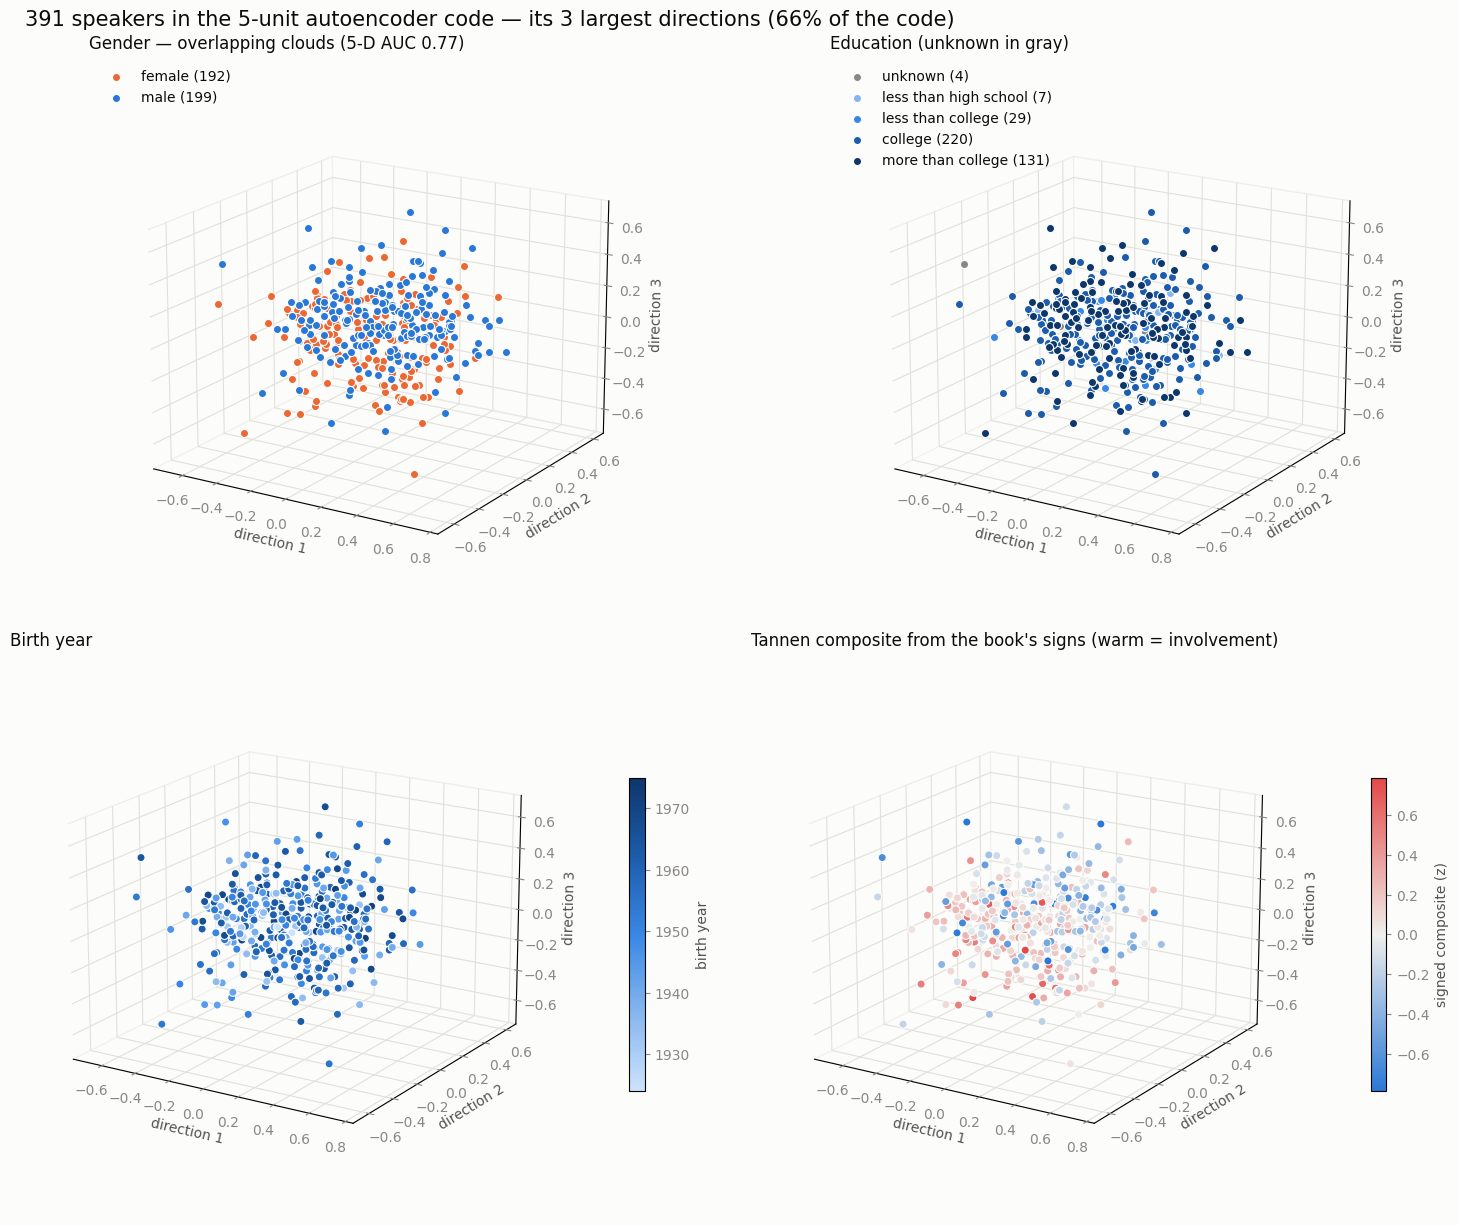

In [10]:
disp = PCA(n_components=3).fit(Z)
D3 = disp.transform(Z)
SHOWN = disp.explained_variance_ratio_.sum()
print(f"the 3-D view shows {SHOWN:.0%} of the {K}-unit code's variance")
EDU_RAMP = {0: "#86b6ef", 1: "#3987e5", 2: "#1c5cab", 3: "#0d366b"}
EDU_NAMES = {0: "less than high school", 1: "less than college", 2: "college", 3: "more than college"}
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_blue_red", [BLUE, "#f0efec", "#e34948"])
kw = dict(s=34, edgecolors=SURF, linewidths=0.8, depthshade=False)
def panel(pos, title, grid=(2, 2), labels=("direction 1", "direction 2", "direction 3")):
    ax = fig.add_subplot(*grid, pos, projection="3d", facecolor=SURF)
    ax.view_init(elev=18, azim=-58); ax.set_box_aspect(None, zoom=0.9)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.set_facecolor(SURF); a.pane.set_edgecolor(GRID)
    ax.set_xlabel(labels[0]); ax.set_ylabel(labels[1]); ax.set_zlabel(labels[2])
    ax.set_title(title, color=INK, fontsize=12, loc="left")
    return ax
fig = plt.figure(figsize=(15, 12.5))
ax = panel(1, f"Gender — overlapping clouds ({K}-D AUC {auc_code:.2f})")
for lab, col, m_ in (("female", ORANGE, fem), ("male", BLUE, ~fem)):
    ax.scatter(*D3[m_].T, c=col, label=f"{lab} ({m_.sum()})", **kw)
ax.legend(frameon=False, loc="upper left")
ax = panel(2, "Education (unknown in gray)")
ax.scatter(*D3[~edu_m].T, c=MUTED, label=f"unknown ({(~edu_m).sum()})", **kw)
for lvl, col in EDU_RAMP.items():
    m_ = (DEMO["education"] == lvl).to_numpy()
    ax.scatter(*D3[m_].T, c=col, label=f"{EDU_NAMES[lvl]} ({m_.sum()})", **kw)
ax.legend(frameon=False, loc="upper left")
ax = panel(3, "Birth year")
sc = ax.scatter(*D3.T, c=DEMO["birth_year"], cmap=SEQ, **kw); fig.colorbar(sc, ax=ax, shrink=0.55, pad=0.08, label="birth year")
ax = panel(4, "Tannen composite from the book's signs (warm = involvement)")
lim = np.abs(composite).quantile(0.98)
sc = ax.scatter(*D3.T, c=composite.clip(-lim, lim), cmap=DIV, vmin=-lim, vmax=lim, **kw)
fig.colorbar(sc, ax=ax, shrink=0.55, pad=0.08, label="signed composite (z)")
fig.suptitle(f"391 speakers in the {K}-unit autoencoder code — its 3 largest directions ({SHOWN:.0%} of the code)", x=0.02, ha="left", fontsize=15, color=INK)
plt.tight_layout(); plt.show()

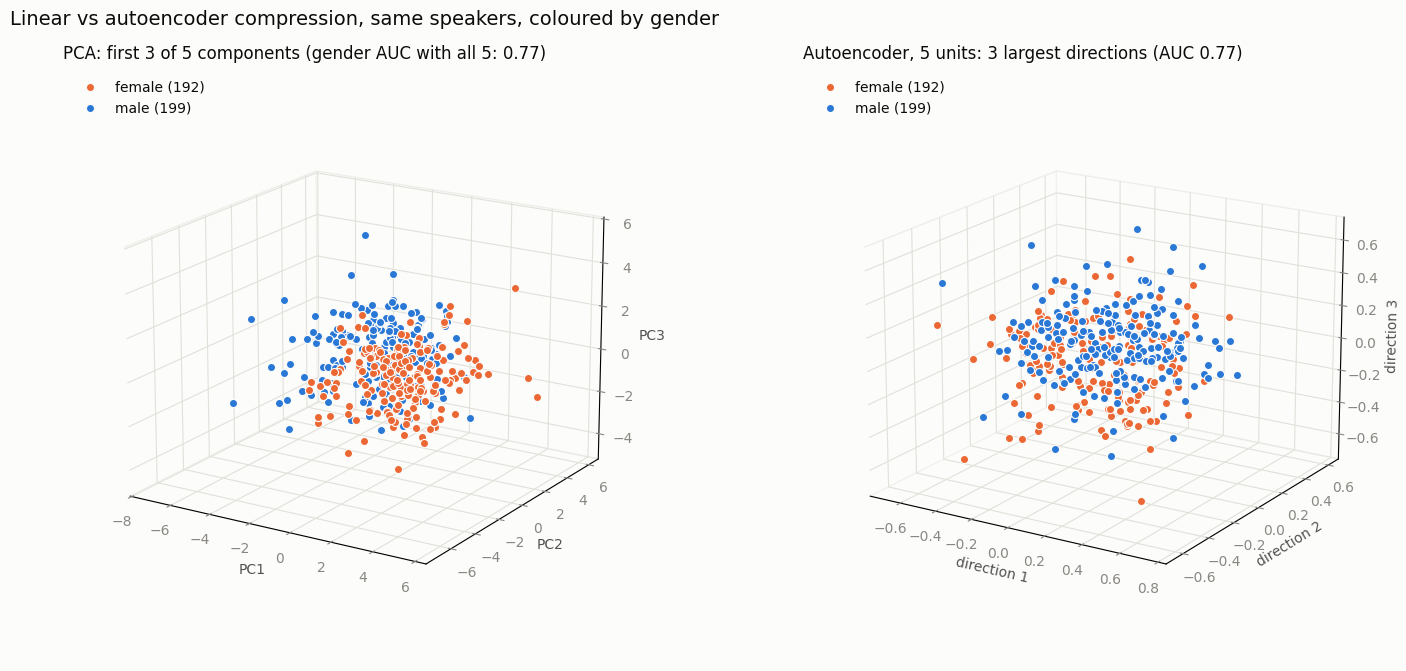

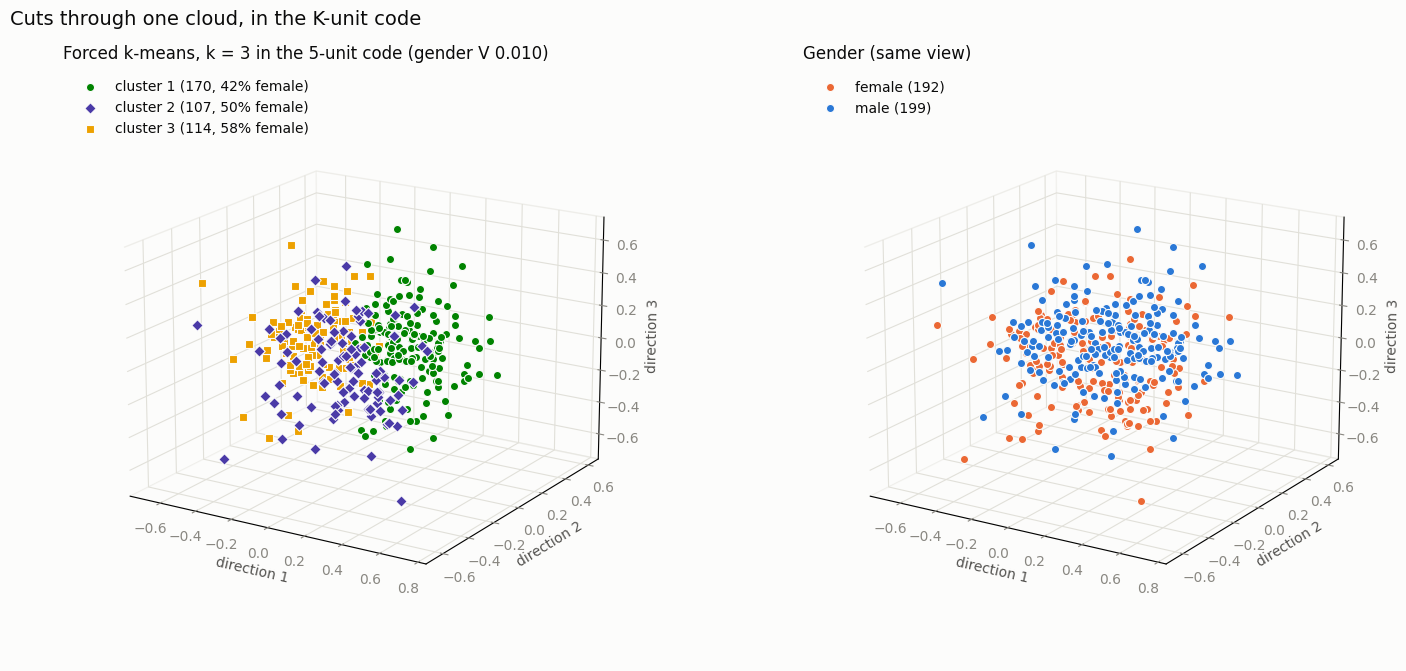

In [11]:
# PCA's own map beside the autoencoder's, then the forced k = 3 cuts beside gender.
fig = plt.figure(figsize=(15, 6.8))
ax = panel(1, f"PCA: first 3 of {K} components (gender AUC with all {K}: {auc_pca:.2f})", grid=(1, 2), labels=("PC1", "PC2", "PC3"))
for lab, col, m_ in (("female", ORANGE, fem), ("male", BLUE, ~fem)):
    ax.scatter(*PC[m_, :3].T, c=col, label=f"{lab} ({m_.sum()})", **kw)
ax.legend(frameon=False, loc="upper left")
ax = panel(2, f"Autoencoder, {K} units: 3 largest directions (AUC {auc_code:.2f})", grid=(1, 2))
for lab, col, m_ in (("female", ORANGE, fem), ("male", BLUE, ~fem)):
    ax.scatter(*D3[m_].T, c=col, label=f"{lab} ({m_.sum()})", **kw)
ax.legend(frameon=False, loc="upper left")
fig.suptitle("Linear vs autoencoder compression, same speakers, coloured by gender", x=0.02, ha="left", fontsize=14, color=INK)
plt.tight_layout(); plt.show()
CLUSTER_COLORS, CLUSTER_MARKERS = ["#008300", "#4a3aa7", "#eda100"], ["o", "D", "s"]   # validated all-pairs; shape = 2nd channel
k3 = PART[(f"autoencoder {K}-D", 3)]
fig = plt.figure(figsize=(15, 6.8))
ax = panel(1, f"Forced k-means, k = 3 in the {K}-unit code (gender V {v_measure_score(yF, k3):.3f})", grid=(1, 2))
for j in range(3):
    m_ = k3 == j
    ax.scatter(*D3[m_].T, c=CLUSTER_COLORS[j], marker=CLUSTER_MARKERS[j], label=f"cluster {j + 1} ({m_.sum()}, {yF[m_].mean():.0%} female)", **kw)
ax.legend(frameon=False, loc="upper left")
ax = panel(2, "Gender (same view)", grid=(1, 2))
for lab, col, m_ in (("female", ORANGE, fem), ("male", BLUE, ~fem)):
    ax.scatter(*D3[m_].T, c=col, label=f"{lab} ({m_.sum()})", **kw)
ax.legend(frameon=False, loc="upper left")
fig.suptitle("Cuts through one cloud, in the K-unit code", x=0.02, ha="left", fontsize=14, color=INK)
plt.tight_layout(); plt.show()

In [12]:
payload = {"caller": [int(c) for c in SPK.index], "x": np.round(D3[:, 0], 4).tolist(), "y": np.round(D3[:, 1], 4).tolist(),
           "z": np.round(D3[:, 2], 4).tolist(), "sex": DEMO["sex"].str.lower().tolist(), "education": DEMO["education"].astype(int).tolist(),
           "birth_year": DEMO["birth_year"].astype(int).tolist(), "dialect": DEMO["dialect"].str.title().tolist(),
           "calls": n_sides.astype(int).tolist(), "composite": composite.round(3).tolist(),
           "k2": PART[(f"autoencoder {K}-D", 2)].tolist(), "k3": PART[(f"autoencoder {K}-D", 3)].tolist()}
out_html = write_map_html(DERIVED / "nb09_map_3d.html", payload, title="Switchboard speaker map — Horn-sized autoencoder",
                          subtitle=(f"391 speakers · {len(FEATS)} features · PCA + Horn → K = {K} · {K}-unit autoencoder (medoid of "
                                    f"{AE_SEEDS} restarts), shown along its 3 largest directions ({SHOWN:.0%} of the code) · gender AUC "
                                    f"{auc_code:.2f} · {'one cloud' if k_code == 1 else f'{k_code} BIC-preferred groups'} (BIC k = {k_code})"),
                          axis_labels=("direction 1", "direction 2", "direction 3"))
print(f"wrote {out_html} ({out_html.stat().st_size / 1024:.0f} KB)")

wrote /Users/dainbrownlow/switchboard/utterances_v2/derived/nb09_map_3d.html (102 KB)


## S7 — Sensitivity: the same two alternative roll-ups as NB08

**A** — only callers seen in ≥3 calls, plain caller means (no shrinkage); **B** — each side value first
stripped of its feature's average partner-sex shift, then NB08's Kelley roll-up (ICCs recomputed on the
adjusted values). Both through the same K-unit autoencoder settings (medoid of 20 restarts). Then NB08's
density check: distance from the code's centroid against the number of calls behind each speaker.

In [13]:
def medoid_code(Xv, k):
    cs = [encode(fit_ae(Xv, s, H, ALPHA, k=k), Xv) for s in range(AE_SEEDS)]
    ds = [pdist(z) for z in cs]
    Mv = np.array([[spearmanr(ds[i], ds[j])[0] if i != j else np.nan for j in range(AE_SEEDS)] for i in range(AE_SEEDS)])
    return cs[int(np.nanargmax(np.nanmean(Mv, 1)))]
def headline(Zv, Xv, D):
    y, e = D["female"].to_numpy(), D["education"].isin([0, 1, 2, 3]).to_numpy()
    return [gmm_best_k(Zv, "full")[0], gmm_best_k(Xv, "tied")[0],
            np.mean([stat_gender(Zv, y, s) for s in range(CV_SEEDS)]), np.mean([stat_gender(Xv, y, s) for s in range(CV_SEEDS)]),
            np.mean([stat_r2(Zv[e], D["education"].to_numpy(float)[e], s) for s in range(CV_SEEDS)]),
            np.mean([stat_r2(Xv, D["birth_year"].to_numpy(float), s) for s in range(CV_SEEDS)])]
SIDEF = SIDE[["caller", *FEATS]]
keep = n_sides.index[n_sides >= 3]
CA = SIDEF[SIDEF["caller"].isin(keep)].groupby("caller")[FEATS].mean()
XA = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(CA.fillna(CA.mean()))
ZA = medoid_code(XA, K)
S_female, S_pfemale = SIDE["female"].to_numpy(), SIDE["partner_female"].to_numpy()
adj, icc_adj = SIDEF.copy(), {}
for f in FEATS:
    v = SIDEF[f].to_numpy(); ok = ~np.isnan(v)
    b = np.linalg.lstsq(np.column_stack([np.ones(ok.sum()), S_female[ok], S_pfemale[ok]]), v[ok], rcond=None)[0]
    adj[f] = v - b[2] * S_pfemale
    d = adj[["caller", f]].dropna(); d = d[d["caller"].map(d["caller"].value_counts()) >= 2]
    icc_adj[f] = icc1(d[f].to_numpy(), d["caller"].to_numpy())
CB, _ = kelley_table(adj, FEATS, pd.Series(icc_adj))
XB = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(CB.loc[SPK.index, FEATS])
ZB = medoid_code(XB, K)
SENS = pd.DataFrame({"primary (391, Kelley)": [k_code, k_full, auc_code, auc_full, stat("education 0–3 (R²)", f"autoencoder {K}-D"),
                                              stat("birth year (R²)", "full 25-D")],
                     f"A: ≥3 calls ({len(CA)}, plain means)": headline(ZA, XA, DEMO.loc[CA.index]),
                     "B: partner-sex adjusted (391)": headline(ZB, XB, DEMO)},
                    index=[f"best k, {K}-D code", "best k, full space", f"gender AUC, {K}-D code", "gender AUC, full space",
                           f"education R², {K}-D code", "birth-year R², full space"])
print(SENS.round(3).to_string())
_rad = lambda z: np.linalg.norm(z - z.mean(0), axis=1)
RADIUS = {f"{K}-D code (primary)": spearmanr(_rad(Z), n_sides)[0], f"{K}-D code, variant A (no shrinkage)": spearmanr(_rad(ZA), n_sides.loc[CA.index])[0]}
print("radius vs number of calls (Spearman): " + "; ".join(f"{k} {v:+.2f}" for k, v in RADIUS.items()) + f"  {elapsed()}")

                           primary (391, Kelley)  A: ≥3 calls (220, plain means)  B: partner-sex adjusted (391)
best k, 5-D code                           1.000                           1.000                          1.000
best k, full space                         1.000                           1.000                          1.000
gender AUC, 5-D code                       0.768                           0.791                          0.759
gender AUC, full space                     0.806                           0.850                          0.799
education R², 5-D code                     0.002                          -0.007                          0.002
birth-year R², full space                  0.111                           0.101                          0.111
radius vs number of calls (Spearman): 5-D code (primary) +0.50; 5-D code, variant A (no shrinkage) -0.18  [369 s]


## S8 — Verdicts, the bottleneck-size comparison, exports

In [14]:
def row(claim, value, checks):
    return {"claim": claim, "value": value, "checks": checks}
_gv = VM[(VM["labels"] == "gender") & (VM["space"] == f"autoencoder {K}-D")]
V = pd.DataFrame([
    row("Horn's K", f"K = {K} ({TAB['cumulative %'].iloc[K - 1]:.1f}% of variance)",
        f"shuffle null K = {HP['K']}; mean rule K = {HN['K_mean']}; 80% subsamples: K = {K} in {(KSUB == K).mean():.0%}, K = {K + 1} in {(KSUB == K + 1).mean():.0%}"),
    row(f"{K}-unit autoencoder fit", f"held-out R² {RECON[f'autoencoder, {K} units']:.2f}",
        f"PCA {K}: {RECON[f'PCA, {K} components']:.2f}; 3-unit AE: {RECON['autoencoder, 3 units (NB08)']:.2f}; shuffled data: "
        f"{RECON[f'autoencoder, {K} units, column-shuffled data']:.2f}; restarts distance ρ median {STAB['dist_rho_median']:.2f}"),
    row("Clusters", f"BIC k = {k_code} ({K}-D code), {CL[f'PCA {K}-D'][0]} (PCA), {k_full} (full)",
        f"dip p {CL[f'autoencoder {K}-D'][3]:.2f}; null k = 1 in {(NULL.k_code == 1).mean():.0%}; t-SNE k {tsne_k} vs t-SNE of one-blob twins {tsne_null_k}; "
        f"power ≥50% from Δ ≈ {POWER.loc[POWER.iloc[:, 1] >= 0.5, 'Mahalanobis Δ'].min()}; variants A/B k = {int(SENS.iloc[0, 1])}/{int(SENS.iloc[0, 2])}"),
    row("Gender", f"AUC {auc_code:.2f} ({K}-D code) / {auc_pca:.2f} (PCA {K}) / {auc_full:.2f} (full)",
        f"FDR p {DEMO_TESTS.iloc[0]['p (BH-FDR)']:.4f}; restarts {auc_seeds.min():.2f}–{auc_seeds.max():.2f}; variants {SENS.iloc[2, 1]:.2f} / {SENS.iloc[2, 2]:.2f}"),
    row("Education", f"R² {stat('education 0–3 (R²)', f'autoencoder {K}-D'):.3f} / {stat('education 0–3 (R²)', f'PCA {K}-D'):.3f} / {stat('education 0–3 (R²)', 'full 25-D'):.3f}",
        "FDR p " + " / ".join(f"{p:.3f}" for p in DEMO_TESTS.loc[DEMO_TESTS.demographic == 'education 0–3 (R²)', 'p (BH-FDR)'])),
    row("Birth year", f"R² {stat('birth year (R²)', f'autoencoder {K}-D'):.3f} / {stat('birth year (R²)', f'PCA {K}-D'):.3f} / {stat('birth year (R²)', 'full 25-D'):.3f}",
        "FDR p " + " / ".join(f"{p:.3f}" for p in DEMO_TESTS.loc[DEMO_TESTS.demographic == 'birth year (R²)', 'p (BH-FDR)'])),
    row("Dialect region", f"macro AUC {stat('dialect region (macro AUC)', f'autoencoder {K}-D'):.3f} / {stat('dialect region (macro AUC)', f'PCA {K}-D'):.3f} / {stat('dialect region (macro AUC)', 'full 25-D'):.3f}",
        "FDR p " + " / ".join(f"{p:.3f}" for p in DEMO_TESTS.loc[DEMO_TESTS.demographic == 'dialect region (macro AUC)', 'p (BH-FDR)'])),
    row("Forced clusters vs demographics", f"gender V {_gv.V.min():.2f}–{_gv.V.max():.2f} (k 2–8; shuffled ≈ {_gv['V shuffled'].mean():.3f})",
        f"best gender split V {CEILING[f'autoencoder {K}-D']:.2f}; nothing beyond gender (min q {CMI['q (BH-FDR)'].min():.2f}); "
        f"region significant at any k: {bool((VM.loc[VM['labels'] == 'region', 'q (BH-FDR)'] < .05).any())}"),
    row("Book-signed composite", f"read-out R² {READ[f'autoencoder {K}']:.2f} ({K}-D code)",
        f"PCA {K} {READ[f'PCA {K}']:.2f}; 3-unit AE {READ['autoencoder 3 (NB08)']:.2f}; full {READ['full 25-D']:.2f}"),
])
with pd.option_context("display.max_colwidth", 220, "display.width", 260):
    print(V.to_string(index=False))

# The bottleneck-size comparison on identical data: 3 vs K units, autoencoder vs PCA.
def summarize(F, cov="full"):
    return [gmm_best_k(F, cov)[0], np.mean([stat_gender(F, yF, s) for s in range(CV_SEEDS)]),
            np.mean([stat_r2(F[edu_m], DEMO["education"].to_numpy(float)[edu_m], s) for s in range(CV_SEEDS)]),
            np.mean([stat_r2(F, DEMO["birth_year"].to_numpy(float), s) for s in range(CV_SEEDS)]), readout(F),
            v_measure_score(yF, KMeans(3, n_init=50, random_state=0).fit_predict(F))]
CMP = pd.DataFrame({"autoencoder 3 (NB08)": summarize(Z3u), f"autoencoder {K}": summarize(Z), "PCA 3": summarize(PC3),
                    f"PCA {K}": summarize(PC), "full 25-D": summarize(X, "tied")},
                   index=["BIC-preferred k", "gender AUC", "education R²", "birth-year R²", "composite read-out R²", "gender V (k-means k = 3)"])
CMP.loc["held-out reconstruction R²"] = [RECON["autoencoder, 3 units (NB08)"], RECON[f"autoencoder, {K} units"], RECON["PCA, 3 components"],
                                         RECON[f"PCA, {K} components"], 1.0]
print("\n" + CMP.round(3).to_string())

EXPORT = pd.DataFrame(Z, columns=[f"ae{j + 1}" for j in range(K)], index=SPK.index) \
    .join(pd.DataFrame(PC, columns=[f"pc{j + 1}" for j in range(K)], index=SPK.index)) \
    .join(pd.DataFrame(D3, columns=["view1", "view2", "view3"], index=SPK.index)).join(DEMO).assign(n_sides=n_sides, tannen_composite=composite)
EXPORT.to_csv(DERIVED / "nb09_speaker_map.csv")
print(f"\nexports → {DERIVED}: nb09_speaker_map.csv ({EXPORT.shape[0]}×{EXPORT.shape[1]}), nb09_map_3d.html · total runtime {elapsed()}")

                          claim                                            value                                                                                                                                          checks
                       Horn's K                        K = 5 (46.5% of variance)                                                                 shuffle null K = 5; mean rule K = 6; 80% subsamples: K = 5 in 58%, K = 6 in 38%
         5-unit autoencoder fit                                 held-out R² 0.42                                                              PCA 5: 0.43; 3-unit AE: 0.30; shuffled data: 0.18; restarts distance ρ median 0.95
                       Clusters          BIC k = 1 (5-D code), 1 (PCA), 1 (full) dip p 0.99; null k = 1 in 100%; t-SNE k [3, 3, 3, 3, 2] vs t-SNE of one-blob twins [4, 1, 2, 3, 2]; power ≥50% from Δ ≈ 5; variants A/B k = 1/1
                         Gender AUC 0.77 (5-D code) / 0.77 (PCA 5) / 0.81 (full)                    


                            autoencoder 3 (NB08)  autoencoder 5  PCA 3  PCA 5  full 25-D
BIC-preferred k                            1.000          1.000  1.000  1.000      1.000
gender AUC                                 0.771          0.768  0.772  0.768      0.806
education R²                               0.008          0.002  0.008  0.002      0.005
birth-year R²                             -0.006          0.015  0.000  0.014      0.111
composite read-out R²                      0.761          0.805  0.772  0.819      1.000
gender V (k-means k = 3)                   0.094          0.010  0.069  0.077      0.080
held-out reconstruction R²                 0.298          0.415  0.310  0.429      1.000

exports → /Users/dainbrownlow/switchboard/utterances_v2/derived: nb09_speaker_map.csv (391×20), nb09_map_3d.html · total runtime [372 s]


## S9 — What this shows (plain summary of the 2026-09-29 run)

**Horn keeps 5 components.** Five directions carry more variance than random data of the same size gives
— 46.5% of the total. The 6th misses by a hair (eigenvalue 1.250 vs threshold 1.256), and Horn's older mean
rule keeps 6. On 80% subsamples of speakers the answer is 5 in 58% and 6 in 38% (7 in 4%). Resampling
*with* replacement would have been useless here: on pure noise it invents 3–12 components, where
subsampling correctly finds 0 every time.

**The five PCA components:** PC1 (13.4%) cooperative overlap, appreciations, continuers and laughter vs slow
floor transfers and long units; PC2 (12.3%) voluble, fast, self-repeating talk vs laughter, questions and
filled pauses; PC3 (7.7%) disfluency — restarts, filled pauses, within-turn pauses; PC4 (6.9%) hedges,
obstructive overlaps, pronouns and questions vs cooperative overlap; PC5 (6.2%) opinions, completions and
hedges vs latching.

**The autoencoder adds nothing PCA doesn't have.** With 5 units it rebuilds 41.5% of held-out variance;
PCA with 5 components rebuilds 42.9% (at 3: 29.8% vs 31.0%). Every autoencoder unit is 98–99% predictable
from the 5 PCA scores. The relations among these 25 features are linear, so the network learns PCA's
subspace, slightly less efficiently. NB08's 3-unit map is reproduced here to 1e-8.

**Five dimensions instead of three:** held-out reconstruction .30 → .42; the book-signed composite .76 →
.81 recoverable; gender unchanged (AUC .77); birth year starts to register (R² .015) but stays far below
the .11 the full feature set carries.

**Still one cloud.** One Gaussian component in the 5-unit code, the 5 PCA scores and the full space; the
distance dip test finds nothing (p ≥ .99); 30 structureless twins give the same. t-SNE of the 5-unit code
does show 2–3 groups — but t-SNE of the structureless twins shows 1–4, so those groups are t-SNE's
drawing, not the speakers'. Power: two planted groups are seen from Δ ≈ 5 (75% / 60%), never at 4.

**Demographics.** Gender AUC .77 in both 5-D compressions and .81 in the full space (Δ ≈ 1.0–1.2) — carried
by unit 3 (r −.46: long, disfluent units vs laughter, cooperative overlap, appreciations and pronouns).
Education reaches FDR p .04 but explains at most 0.5% of variance. Region is faintly above chance in the
two 5-D spaces (macro AUC .54, FDR p .04) but at chance in the full space (.50) and in NB08's 3-D map — not a
stable finding.

**Forced clusters.** Cut in the 5 PCA scores, k-means follows gender as it did in NB08 (V .05–.10 at every
k). Cut in the 5-unit code — the same subspace, scaled differently — it follows gender weakly and
inconsistently (V .01–.07; the k = 3 median over restarts is .035). Arbitrary cuts of one cloud depend on
how the cloud is stretched. Nothing beyond gender at any k (smallest FDR q .11).

**Limits.** NB08's, plus: the 3-D pictures show 66% of the 5-unit code; shrinkage pulls one-call speakers
toward the centre more strongly here (radius–calls ρ +.50; −.18 without shrinkage).